# Reading the database 


In [1]:
from Functions import *
from Rewiring_functions import *

In [2]:
Ilist=read_database()

In [3]:
Ilist

Pollinator_gen_sp           Plant_gen_sp  Frequency
Site_ID           Year                                                        
aznalcazar        2015      andrena flavipes   cistus monspeliensis          1
                  2015    andrena nigroaenea         cistus crispus          1
                  2015  andrena nitidiuscula         cistus crispus          1
                  2015            andrena sp     teucrium fruticans          1
                  2015  andrena tenuistriata         cistus crispus          1
...                                      ...                    ...        ...
villamanrique sur 2022        lobonyx aeneus    cistus salviifolius          2
                  2022        lobonyx aeneus     lavandula stoechas          1
                  2022      nomada succincta     lavandula stoechas          1
                  2022   panurgus cephalotes  andryala integrifolia          2
                  2022   xylocopa cantabrita     lavandula stoechas          1

[3285 rows x 3 columns]

In [4]:
#create a dictionary with the matrix of each site-eachyear
networks={}
for site in Sites:
    #print(site)
    networks[site]={}
    for year in Years:
        Imat = Ilist.xs((site,year),level=["Site_ID", "Year"]).pivot(index="Plant_gen_sp",columns="Pollinator_gen_sp",values="Frequency").fillna(0)
        networks[site][year]=Imat


Now we select any two networks to quantify how they change.

In [5]:
#hay que elegir sitio y año!
site=Sites[0] #2,1/9.3/10/6 /0.4
year=Years[0]#4
web1=networks[site][year]
web2=networks[site][year+1]

In [6]:
Years

[2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]

# Quantification of interaction reorganization - UNWEIGHTED


In [7]:
#rewiring_py_new(web1,web2)
I_df,N_df=rewiring_freq_py(web1, web2)

## Representación gráfica de las 2 matrices

podemos ver que el conteo cualitativo hecho en la función es correcto: 

CN_SI= CN_CI+CN_DI+CN_II = 9 + 3 + 5 =17
GN_GI= GBN_GI+B1N_GI= 3 + 31 = 34 
LN_LI= LBN_LI + L1N_LI= 4 + 25 = 29 

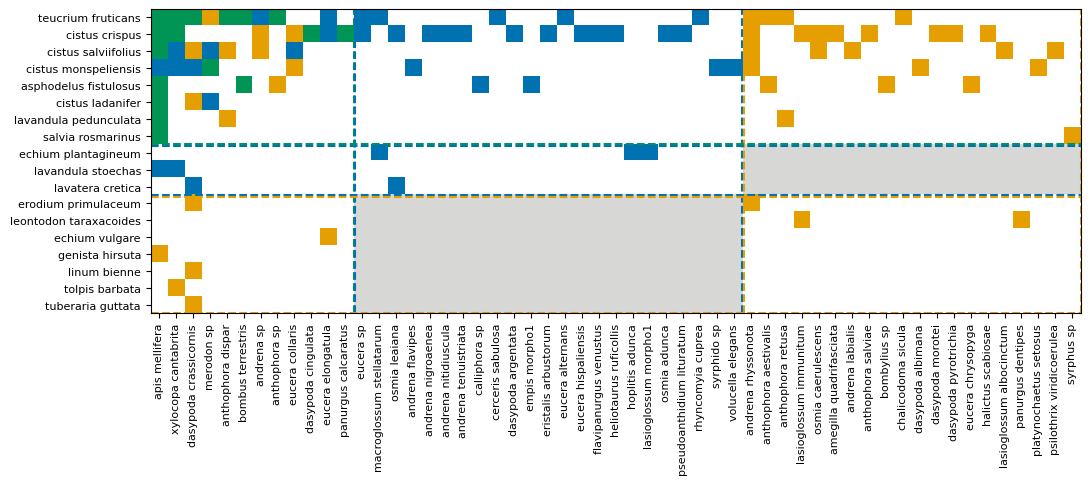

In [8]:
#La identificación la tenemos que hacer en la red NO pesada, que nos permite sabes cuales son las especies permanente sy cuales no
plt.rcParams.update({'font.size': 15})
# Create a figure
fig, ax1 = plt.subplots(figsize=(12, 8))
#plot_betadiversity_matrix_to_ax(web1/web1,web2/web2,ax=ax1)
plot_betadiversity_Wmatrix_to_ax(web1,web2,ax=ax1,weighted=False,names=True)
plt.show()


# Quantification of interaction reorganization - WEIGHTED

In [9]:
changes_df,nodes_df=rewiring_freq_py(web1, web2)
changes_df#.sum(numeric_only=True)

changes_df["metric"].tolist()

['CN_CI',
 'CN_DI',
 'CN_II',
 'CN_LI',
 'CN_GI',
 'L1N_LI',
 'LBN_LI',
 'G1N_GI',
 'GBN_GI']

In [10]:
nodes_df

,metric,n_species
0,PA,12
1,PP,8
2,A1,23
3,P1,3
4,A2,20
5,P2,7


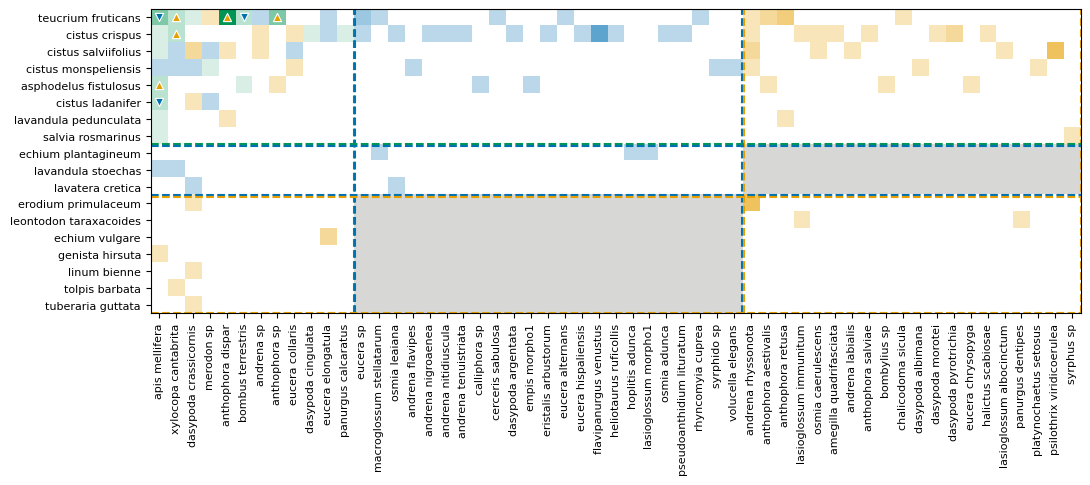

In [11]:
fig, ax1 = plt.subplots(figsize=(12, 8))
plot_betadiversity_Wmatrix_to_ax(web1,web2,ax=ax1,names=True)
plt.show()

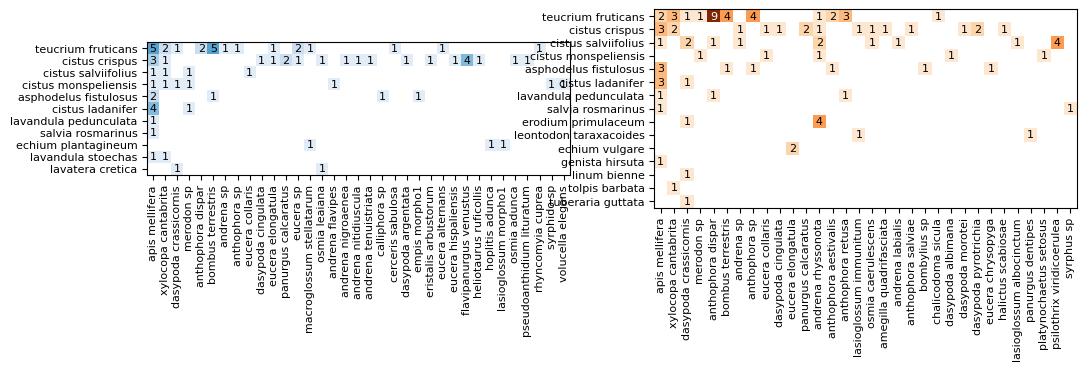

In [12]:
plot_networks_separately_matched_order(web1, web2);

In [13]:
B3,B4,beta_dict2=get_betadiversity_Wnetwork_by_year(networks[site][year+1],networks[site][year+2])#16-17

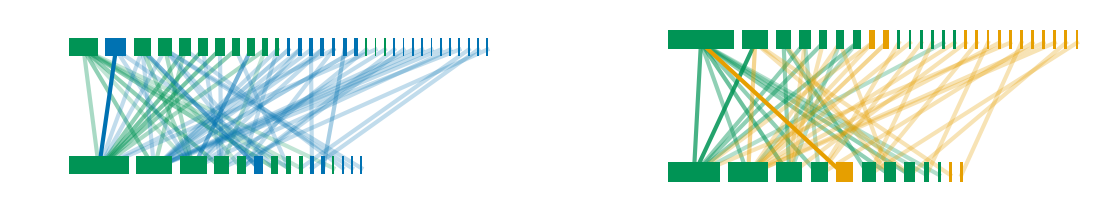

In [14]:
## vamos a hacer una figura con las redes y la matrizs

ncol=2
nrow=1
plt.rcParams.update({'font.size': 25})
fig, axs = plt.subplots(nrow, ncol,figsize=(7*ncol,4.5*nrow),sharey=True)#row


plot_bipartite_Wnetwork_to_ax(B3,draw_labels=False,node_cathegories=beta_dict2,w=1,h=0.3,buffer=8,lw=3,ax=axs[0],edge_color="#0072B2")
plot_bipartite_Wnetwork_to_ax(B4,draw_labels=False,node_cathegories=beta_dict2,w=1,h=0.3,buffer=8,lw=3,ax=axs[1],edge_color="#E69F00")
plt.show()


In [15]:
beta_dict2

{'eucera collaris': 'common',
 'anthophora retusa': 'common',
 'apis mellifera': 'common',
 'eucera chrysopyga': 'common',
 'chalicodoma sicula': 'common',
 'bombus terrestris': 'common',
 'psilothrix viridicoerulea': 'common',
 'andrena rhyssonota': 'common',
 'dasypoda crassicornis': 'common',
 'anthophora sp': 'common',
 'anthophora aestivalis': 'common',
 'lasioglossum albocinctum': 'common',
 'xylocopa cantabrita': 'common',
 'dasypoda albimana': 'y1',
 'platynochaetus setosus': 'y1',
 'panurgus calcaratus': 'y1',
 'osmia caerulescens': 'y1',
 'dasypoda morotei': 'y1',
 'amegilla quadrifasciata': 'y1',
 'lasioglossum immunitum': 'y1',
 'halictus scabiosae': 'y1',
 'anthophora dispar': 'y1',
 'anthophora salviae': 'y1',
 'andrena sp': 'y1',
 'merodon sp': 'y1',
 'eucera elongatula': 'y1',
 'dasypoda pyrotrichia': 'y1',
 'andrena labialis': 'y1',
 'dasypoda cingulata': 'y1',
 'syrphus sp': 'y1',
 'panurgus dentipes': 'y1',
 'bombylius sp': 'y1',
 'chasmatopterus villosulus': 'y2',
 

# Global cuantification of changes

Vamos a hacer la cuantificacion de ambas juntas, auqnue plotearemos por separado para unweighted y weighted. 

Primero guardmos todos los cambios de t1 con t2 para cada sitio. 
Luego lo que vamos a hacer es sacar los cambios uanto son por rewiring (CN_LI + CN_GI) y cuantos por ineracciones entre transient y permanentes (L1N_LI + G1N_GI) y cuantos son por 2 especies que cambian (LBN_LI+GBN_GI). 

Esas variables las queremos normalizar al total de cambios, que son : CN_LI+CN_GI+LBN_LI+L1N_LS+GBN_GI+G1N_GI 


In [16]:
metric=['CN_CI', 'CN_DI', 'CN_II', 'CN_LI', 'CN_GI', 'L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI']
metric_N=["PA","PP","A1","P1","A2","P2"]
mi2=pd.MultiIndex.from_product([Sites,Years[1::],metric],names=["Site_ID", "year","metric"])
Changes_df=pd.DataFrame(index=mi2,columns=["n_interactions","freq_interactions"])
Changes_df.sort_index(inplace=True)
mi2N=pd.MultiIndex.from_product([Sites,Years[1::],metric_N],names=["Site_ID", "year","metric"])
nodes_df=pd.DataFrame(index=mi2N,columns=["n_nodes"])
nodes_df.sort_index(inplace=True)
#Changes_df

for site in Sites:
    for year in Years[0:-1]:
        changes, nodes = rewiring_freq_py(networks[site][year], networks[site][year+1])
        changes = changes.set_index('metric')          # <- AÑADIR esto
        nodes = nodes.set_index('metric')          # <- AÑADIR esto
        for m in changes.index:                        # <- 'm', NO 'metric'
            Changes_df.loc[(site, year+1, m), 'n_interactions'] = changes.loc[m, 'n_interactions']
            Changes_df.loc[(site, year+1, m), 'freq_interactions'] = changes.loc[m, 'freq_sum']
        for m in nodes.index:                        # <- 'm', NO 'metric'
                    nodes_df.loc[(site, year+1, m), 'n_nodes'] = nodes.loc[m, 'n_species']

Changes_df    

n_interactions freq_interactions
Site_ID           year metric                                 
aznalcazar        2016 CN_CI               9              12.0
                       CN_DI               3               5.0
                       CN_GI              10              11.0
                       CN_II               5              13.0
                       CN_LI              10              10.0
...                                      ...               ...
villamanrique sur 2022 CN_LI               1               2.0
                       G1N_GI              6               7.0
                       GBN_GI              0               0.0
                       L1N_LI             15              46.0
                       LBN_LI             10              30.0

[756 rows x 2 columns]

In [17]:
nodes_df

n_nodes
Site_ID           year metric        
aznalcazar        2016 A1          23
                       A2          20
                       P1           3
                       P2           7
                       PA          12
...                               ...
villamanrique sur 2022 A2           5
                       P1           3
                       P2           0
                       PA           7
                       PP           5

[504 rows x 1 columns]

## Unweighted

In [18]:
value_col="n_interactions"    
wide = Changes_df[value_col].unstack('metric')

rewiring = wide['CN_LI'] + wide['CN_GI']
trans_perm = wide['L1N_LI'] + wide['G1N_GI']
trans_trans = wide['LBN_LI'] + wide['GBN_GI']
total = rewiring + trans_perm + trans_trans

props_UW = pd.DataFrame({
    'persistent-persistent': rewiring / total,
    'transient-persistent': trans_perm / total,
    'transient-transient': trans_trans / total,
    'total_changes': total,
})
props_UW


persistent-persistent transient-persistent   
Site_ID           year                                              
aznalcazar        2016              0.240964             0.674699  \
                  2017              0.352113             0.591549   
                  2018              0.349206             0.634921   
                  2019              0.393443             0.590164   
                  2020              0.253968             0.666667   
...                                      ...                  ...   
villamanrique sur 2018              0.230769             0.615385   
                  2019              0.230769             0.615385   
                  2020              0.222222             0.644444   
                  2021              0.173913             0.652174   
                  2022              0.114286                  0.6   

                       transient-transient total_changes  
Site_ID           year                                    
aznalcazar        2016            0.084337            83  
                  2017            0.056338            71  
                  2018            0.015873            63  
                  2019            0.016393            61  
                  2020            0.079365            63  
...                                    ...           ...  
villamanrique sur 2018            0.153846            39  
                  2019            0.153846            39  
                  2020            0.133333            45  
                  2021            0.173913            46  
                  2022            0.285714            35  

[84 rows x 4 columns]

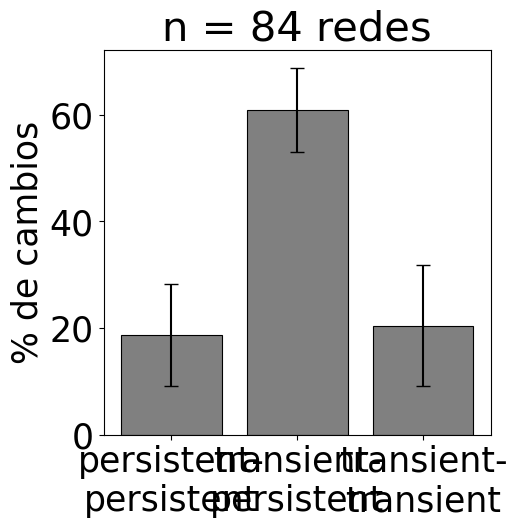

In [19]:
props=props_UW
categories=('persistent-persistent','transient-persistent','transient-transient')
fig, ax = plt.subplots(figsize=(5, 5))
labels = ['persistent-\npersistent','transient-\npersistent','transient-\ntransient']

means = props[list(categories)].mean()
stds = props[list(categories)].std()
n = props[list(categories)].notna().all(axis=1).sum()

x = np.arange(len(categories))
ax.bar(x, means.values * 100, yerr=stds.values * 100, capsize=5,
        color="gray", edgecolor='black', linewidth=0.8)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('% de cambios')
ax.set_title(f'n = {n} redes')
plt.show()

## Weighted

Pa el weighted los que vamos a sacar por en una es peso total del cambio de las persistent-persistent, transient-persistent y trnasient-transient. Para que sea equitativo entre redes vamos a normalizar con la suma total de cambios. 

In [20]:
value_col="freq_interactions"    
wide = Changes_df[value_col].unstack('metric')

rewiring = wide['CN_LI'] + wide['CN_GI']
trans_perm = wide['L1N_LI'] + wide['G1N_GI']
trans_trans = wide['LBN_LI'] + wide['GBN_GI']
total = rewiring + trans_perm + trans_trans

props_WN = pd.DataFrame({
    'persistent-persistent': rewiring / total,
    'transient-persistent': trans_perm / total,
    'transient-transient': trans_trans / total,
    'total_changes': total,
})
props_WN

persistent-persistent transient-persistent   
Site_ID           year                                              
aznalcazar        2016                  0.21                 0.69  \
                  2017              0.305263             0.642105   
                  2018              0.348837             0.639535   
                  2019              0.470588             0.517647   
                  2020              0.296296              0.62963   
...                                      ...                  ...   
villamanrique sur 2018              0.230769             0.557692   
                  2019              0.265306             0.510204   
                  2020              0.277778             0.611111   
                  2021              0.265957              0.62766   
                  2022              0.056818             0.602273   

                       transient-transient total_changes  
Site_ID           year                                    
aznalcazar        2016                 0.1         100.0  
                  2017            0.052632          95.0  
                  2018            0.011628          86.0  
                  2019            0.011765          85.0  
                  2020            0.074074          81.0  
...                                    ...           ...  
villamanrique sur 2018            0.211538          52.0  
                  2019             0.22449          49.0  
                  2020            0.111111          54.0  
                  2021            0.106383          94.0  
                  2022            0.340909          88.0  

[84 rows x 4 columns]

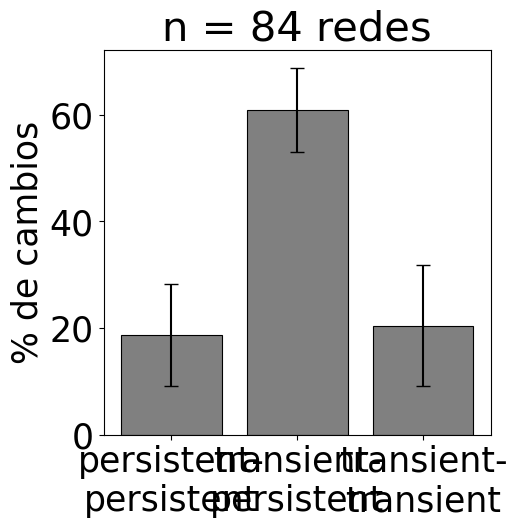

In [21]:
props_WN
categories=('persistent-persistent','transient-persistent','transient-transient')
fig, ax = plt.subplots(figsize=(5, 5))
labels = ['persistent-\npersistent','transient-\npersistent','transient-\ntransient']

means = props[list(categories)].mean()
stds = props[list(categories)].std()
n = props[list(categories)].notna().all(axis=1).sum()

x = np.arange(len(categories))
ax.bar(x, means.values * 100, yerr=stds.values * 100, capsize=5,
        color="gray", edgecolor='black', linewidth=0.8)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('% de cambios')
ax.set_title(f'n = {n} redes')
plt.show()

Esta es muy parecida a la no pesada pq importa mucho que el numero en si mismo de interacciones se va sumando y al final determina cuanto cambia. 

Lo que nos interesa es saber si las interacciones entre transient o permanentes tienen per se más frecuencia, por ejemplo

In [22]:
mean_str_df=Changes_df["freq_interactions"]/Changes_df["n_interactions"]

Mean=mean_str_df.groupby("metric").mean()
Std=mean_str_df.groupby("metric").std()

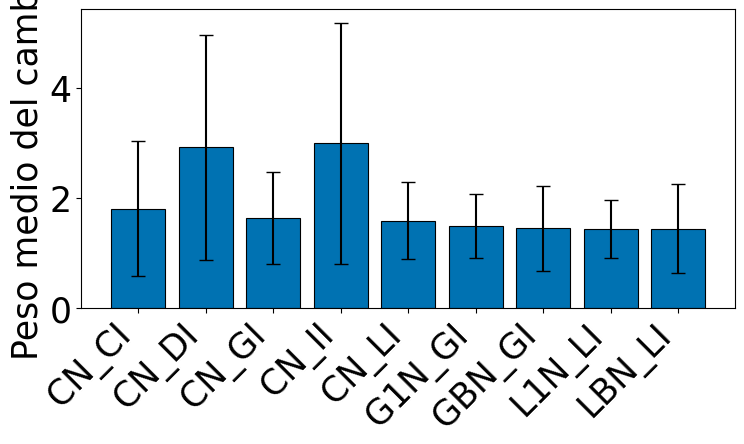

In [23]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(Mean))
ax.bar(x, Mean.values, yerr=Std.values, capsize=5,
       color="#0072B2", edgecolor="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(Mean.index, rotation=45, ha='right')
ax.set_ylabel("Peso medio del cambio")
plt.tight_layout()

<Axes: ylabel='freq_interactions'>

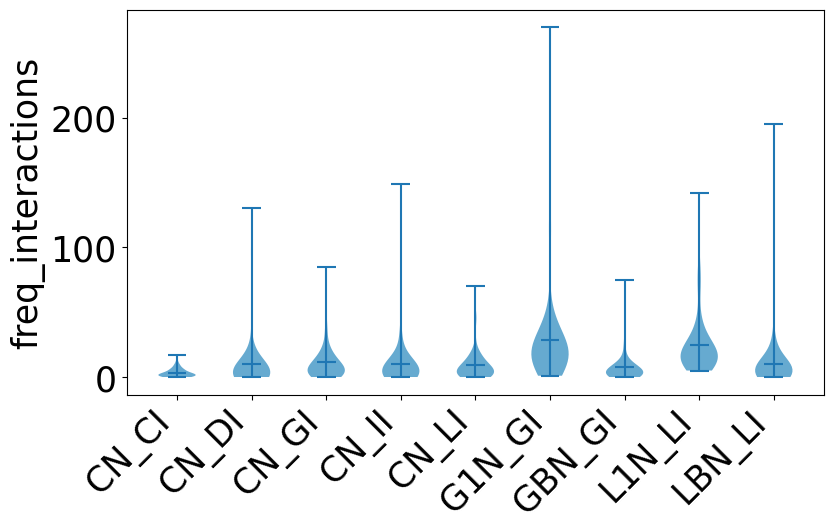

In [24]:
def plot_changes_violin(Changes_df, value_col="freq_interactions",
                         metric_order=None, ax=None, color="#0072B2",
                         color_by_site=False, jitter=0.06, point_size=25,
                         site_palette=None, legend=True, zero_offset=None):
    """
    Violin plot de la distribucion de `value_col` para cada categoria de cambio,
    usando TODAS las redes (todas las filas Site_ID/year) de Changes_df.

    Parameters
    ----------
    color_by_site : bool
        Si True, superpone los puntos individuales (una red = un punto) encima
        del violin, coloreados por Site_ID, con un poco de jitter horizontal
        para que no se amontonen.
    jitter : float
        Dispersion horizontal maxima de los puntos (en unidades del eje x).
    site_palette : dict {site: color} o None
        Si None, se genera automaticamente con un colormap cualitativo.
    zero_offset : float o None
        Si no es None, sustituye los valores EXACTAMENTE 0 por este numero
        (p.ej. 0.1) antes de graficar. Necesario para usar escala logaritmica
        (ax.set_yscale('log')), ya que log(0) no existe. Los valores >0 no se
        tocan -- solo se desplazan los ceros para que sean visibles cerca del
        fondo del grafico en vez de desaparecer.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 5))

    if metric_order is None:
        metric_order = Changes_df.index.get_level_values('metric').unique().tolist()

    data_by_metric = [
        Changes_df.xs(m, level='metric')[value_col].dropna().astype(float)
        for m in metric_order
    ]

    if zero_offset is not None:
        data_by_metric = [d.replace(0, zero_offset) for d in data_by_metric]

    parts = ax.violinplot([d.values for d in data_by_metric], showmeans=True, showextrema=True)
    for pc in parts['bodies']:
        pc.set_facecolor(color)
        pc.set_alpha(0.4 if color_by_site else 0.6)

    if color_by_site:
        sites = Changes_df.index.get_level_values('Site_ID').unique().tolist()
        if site_palette is None:
            cmap = plt.get_cmap('tab10' if len(sites) <= 10 else 'tab20')
            site_palette = {s: cmap(i % cmap.N) for i, s in enumerate(sites)}

        rng = np.random.default_rng(0)  # semilla fija -> jitter reproducible
        plotted_sites = set()
        for i, series in enumerate(data_by_metric, start=1):
            site_labels = series.index.get_level_values('Site_ID')
            x = i + rng.uniform(-jitter, jitter, size=len(series))
            for site in site_labels.unique():
                mask = site_labels == site
                label = site if (legend and site not in plotted_sites) else None
                ax.scatter(x[mask], series.values[mask], color=site_palette[site],
                           s=point_size, edgecolor='black', linewidth=0.4,
                           zorder=3, label=label)
                plotted_sites.add(site)

        if legend:
            ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8, title='Site')

    ax.set_xticks(np.arange(1, len(metric_order) + 1))
    ax.set_xticklabels(metric_order, rotation=45, ha='right')
    ax.set_ylabel(value_col)

    return ax
plot_changes_violin(Changes_df)

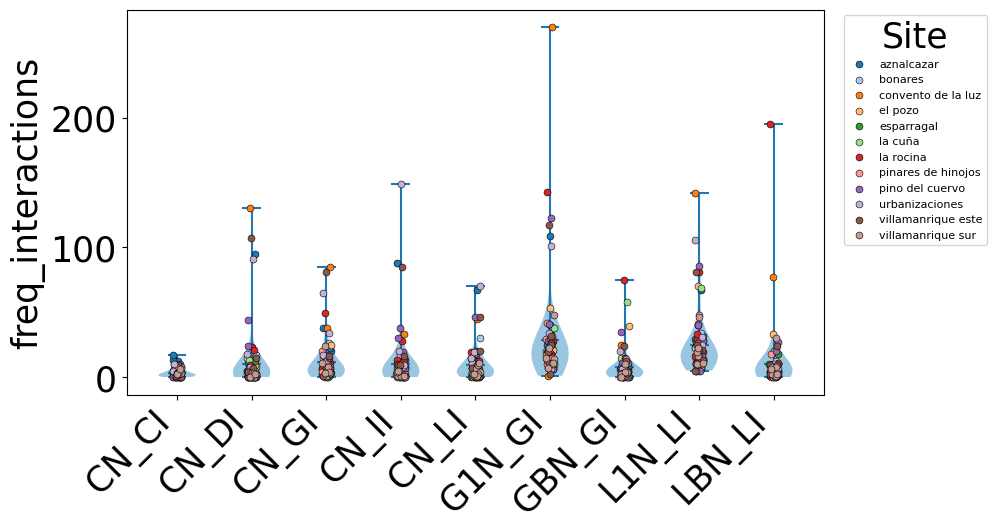

In [25]:
plot_changes_violin(Changes_df, value_col="freq_interactions", color_by_site=True);

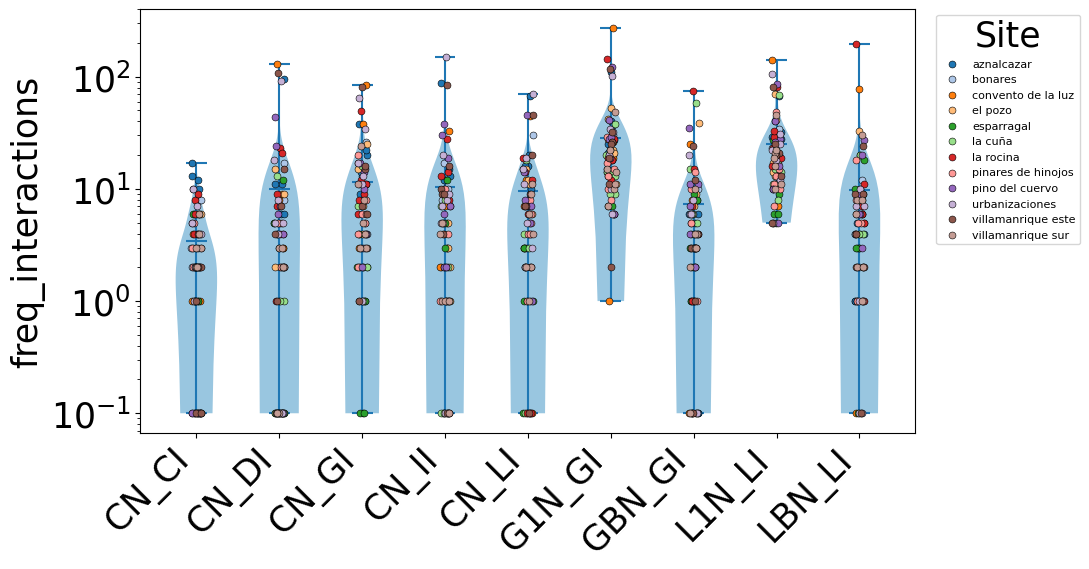

In [26]:
fig, ax = plt.subplots(figsize=(10, 5.5))
plot_changes_violin(Changes_df, value_col="freq_interactions", ax=ax, color_by_site=True, zero_offset=0.1)
ax.set_yscale('log')